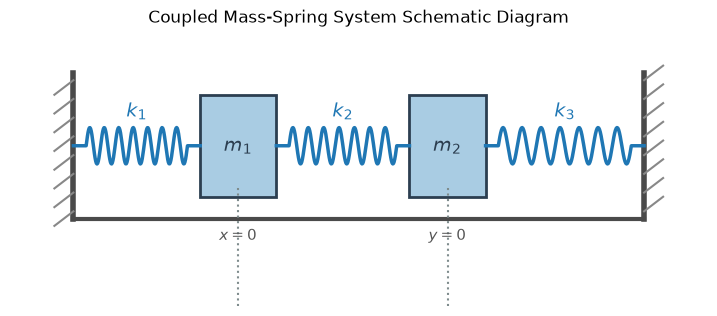

In [5]:
#THIS CELL CREATES THE SYSTEM SCHEMATIC
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# =====================================================================
# IMAGE 1: STANDALONE SYSTEM SCHEMATIC
# =====================================================================
fig1, ax = plt.subplots(figsize=(9, 3.5))

# Draw ground line and side walls
ax.plot([0.5, 9.5], [1.0, 1.0], color='#4A4A4A', lw=3)       # Floor
ax.plot([0.5, 0.5], [1.0, 3.0], color='#4A4A4A', lw=4)       # Left wall
ax.plot([9.5, 9.5], [1.0, 3.0], color='#4A4A4A', lw=4)       # Right wall

# Add cross-hatching to the walls
for y in np.linspace(1.1, 2.9, 8):
    ax.plot([0.2, 0.5], [y - 0.2, y], color='#888888', lw=1.5)
    ax.plot([9.5, 9.8], [y, y + 0.2], color='#888888', lw=1.5)

# Function to generate spring coil geometry dynamically
def get_spring_coords(x1, x2, y, num_coils=7, amp=0.25):
    x = np.linspace(x1, x2, 200)
    y_coords = np.full_like(x, y)
    lead_in = 0.2
    mask = (x > x1 + lead_in) & (x < x2 - lead_in)
    coils_x = x[mask]
    theta = np.linspace(0, num_coils * 2 * np.pi, len(coils_x))
    y_coords[mask] = y + amp * np.sin(theta)
    return x, y_coords

# Draw Springs
x_s1, y_s1 = get_spring_coords(0.5, 2.5, 2.0)
ax.plot(x_s1, y_s1, color='#1f77b4', lw=2.5)
ax.text(1.5, 2.4, r'$k_1$', fontsize=14, color='#1f77b4', ha='center')

x_s2, y_s2 = get_spring_coords(3.7, 5.8, 2.0)
ax.plot(x_s2, y_s2, color='#1f77b4', lw=2.5)
ax.text(4.75, 2.4, r'$k_2$', fontsize=14, color='#1f77b4', ha='center')

x_s3, y_s3 = get_spring_coords(7.0, 9.5, 2.0)
ax.plot(x_s3, y_s3, color='#1f77b4', lw=2.5)
ax.text(8.25, 2.4, r'$k_3$', fontsize=14, color='#1f77b4', ha='center')

# Draw Mass Blocks
m1 = patches.Rectangle((2.5, 1.3), 1.2, 1.4, edgecolor='#2C3E50', facecolor='#A9CCE3', lw=2)
ax.add_patch(m1)
ax.text(3.1, 2.0, r'$m_1$', fontsize=14, color='#2C3E50', ha='center', va='center', weight='bold')

m2 = patches.Rectangle((5.8, 1.3), 1.2, 1.4, edgecolor='#2C3E50', facecolor='#A9CCE3', lw=2)
ax.add_patch(m2)
ax.text(6.4, 2.0, r'$m_2$', fontsize=14, color='#2C3E50', ha='center', va='center', weight='bold')

# Dashed equilibrium markers
ax.axvline(3.1, ymin=0.0, ymax=0.45, color='#7F8C8D', linestyle=':', lw=1.5)
ax.axvline(6.4, ymin=0.0, ymax=0.45, color='#7F8C8D', linestyle=':', lw=1.5)
ax.text(3.1, 0.7, r'$x = 0$', fontsize=11, color='#555555', ha='center')
ax.text(6.4, 0.7, r'$y = 0$', fontsize=11, color='#555555', ha='center')

ax.set_xlim(-0.5, 10.5)
ax.set_ylim(-0.2, 3.5)
ax.axis('off')
plt.title("Coupled Mass-Spring System Schematic Diagram", fontsize=12, pad=10)
plt.show()



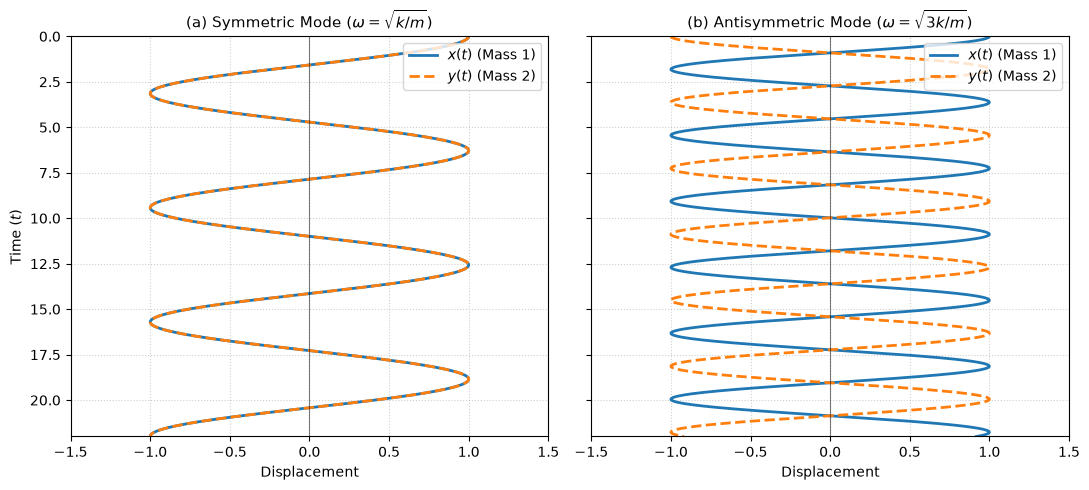

In [4]:
#THIS CELL CREATES TWO EXAMPLES OF VIBRATIONAL MODES FOR THE SYSTEM
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
# IMAGE 2: COMBINED MODES WAVE RESPONSES
# =====================================================================
t = np.linspace(0, 22, 1000)
omega1 = 1.0
omega2 = np.sqrt(3)

# Setup subplots side-by-side in one figure window
fig2, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

# Left Panel: Symmetric Mode
ax1.plot(np.cos(omega1 * t), t, label=r'$x(t)$ (Mass 1)', color='#1f77b4', lw=2)
ax1.plot(np.cos(omega1 * t), t, label=r'$y(t)$ (Mass 2)', color='#ff7f0e', linestyle='--', lw=2)
ax1.set_title(r'(a) Symmetric Mode ($\omega = \sqrt{k/m}$)', fontsize=11)
ax1.set_xlabel('Displacement')
ax1.set_ylabel('Time ($t$)')
ax1.set_xlim(-1.5, 1.5)
ax1.set_ylim(22, 0) # Downward time flow
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.axvline(0, color='black', lw=0.8, alpha=0.5)
ax1.legend(loc='upper right')

# Right Panel: Antisymmetric Mode
ax2.plot(np.cos(omega2 * t), t, label=r'$x(t)$ (Mass 1)', color='#1f77b4', lw=2)
ax2.plot(-np.cos(omega2 * t), t, label=r'$y(t)$ (Mass 2)', color='#ff7f0e', linestyle='--', lw=2)
ax2.set_title(r'(b) Antisymmetric Mode ($\omega = \sqrt{3k/m}$)', fontsize=11)
ax2.set_xlabel('Displacement')
ax2.set_xlim(-1.5, 1.5)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.axvline(0, color='black', lw=0.8, alpha=0.5)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()
